In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills.ipynb")

/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id '4d52d6d9-e745-43b4-9320-6f54aa03165d' detected. Corrected to '5f3f490b'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id 'cb27288e-e39c-424a-a6d9-91246bc5ccb8' detected. Corrected to '0b6226d6'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

**UPDATE THIS LINK**
https://github.com/kellyloveskelp/eds220-hwk3


- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

In [2]:
# FINAL CODE

## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.

## 3. Import libraries

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [4]:
fp = os.path.join('data', 'tl_2026_us_county', 'tl_2026_us_county.shp')
counties = gpd.read_file(fp)


csv = os.path.join('data' , 'Spill_Incidents_20261107.csv')
spills = pd.read_csv(csv)

# Remove county labeled Canada to only query US counties
spills = spills[~spills['County'].str.contains('Canada', case=False)]

<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

_Type your answer here, replacing this text._

In [5]:
#a. Check the dataframe's head
spills.head(3)

,Spill Number,Program Facility Name,Street 1,Street 2,Locality,County,ZIP Code,SWIS Code,DEC Region,Spill Date,Received Date,Contributing Factor,Waterbody,Source,Close Date,Material Name,Material Family,Quantity,Units,Recovered
0,107132,MH 864,RT 119/MILLWOOD RD,NaN,ELMSFORD,Westchester,NaN,6000,3,10/10/2001,10/10/2001,Unknown,NaN,Unknown,10/15/2001,unknown material,Other,10,Gallons,0
1,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,NaN,0
2,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,Pounds,0


In [6]:
#b. Check the data types of the columns
spills.dtypes

Spill Number              int64
Program Facility Name    object
Street 1                 object
Street 2                 object
Locality                 object
County                   object
ZIP Code                 object
SWIS Code                 int64
DEC Region                int64
Spill Date               object
Received Date            object
Contributing Factor      object
Waterbody                object
Source                   object
Close Date               object
Material Name            object
Material Family          object
Quantity                 object
Units                    object
Recovered                object
dtype: object

In [7]:
#c. Check the unique values in the `material_family` column
spills['Material Family'].nunique

<bound method IndexOpsMixin.nunique of 0                      Other
1                      Other
2                      Other
3                  Petroleum
4                  Petroleum
                 ...        
574850    Hazardous Material
574851             Petroleum
574852             Petroleum
574853             Petroleum
574854             Petroleum
Name: Material Family, Length: 574824, dtype: object>

In [8]:
#d. Check the unique values in the `county` column
spills['County'].nunique

<bound method IndexOpsMixin.nunique of 0         Westchester
1              Queens
2              Queens
3               Bronx
4            Sullivan
             ...     
574850       New York
574851       New York
574852       New York
574853       Richmond
574854         Queens
Name: County, Length: 574824, dtype: object>

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [9]:
spills.columns = spills.columns.str.lower().str.replace(' ', '_')
spills.columns

Index(['spill_number', 'program_facility_name', 'street_1', 'street_2',
       'locality', 'county', 'zip_code', 'swis_code', 'dec_region',
       'spill_date', 'received_date', 'contributing_factor', 'waterbody',
       'source', 'close_date', 'material_name', 'material_family', 'quantity',
       'units', 'recovered'],
      dtype='object')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [10]:
spills['spill_date'] = pd.to_datetime(spills['spill_date'])
print(spills.dtypes)

spill_number                      int64
program_facility_name            object
street_1                         object
street_2                         object
locality                         object
county                           object
zip_code                         object
swis_code                         int64
dec_region                        int64
spill_date               datetime64[ns]
received_date                    object
contributing_factor              object
waterbody                        object
source                           object
close_date                       object
material_name                    object
material_family                  object
quantity                         object
units                            object
recovered                        object
dtype: object


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [11]:
spills['spill_date']

0        2001-10-10
1        2004-08-21
2        2004-08-21
3        2002-08-02
4        2003-01-20
            ...    
574850   2004-04-27
574851   1999-07-06
574852   1993-03-02
574853   1990-01-05
574854   2001-06-13
Name: spill_date, Length: 574824, dtype: datetime64[ns]

In [12]:
petr_23_int = spills[spills['spill_date'] >= '2023-01-01'] # Cannot call "and" operator for some reason
petr_23 = petr_23_int[petr_23_int['spill_date'] <= '2023-12-31']
petr_23['spill_date'].sort_values()

382098   2023-01-01
33509    2023-01-01
425492   2023-01-01
38806    2023-01-01
46855    2023-01-01
            ...    
413592   2023-12-31
181251   2023-12-31
307338   2023-12-31
448513   2023-12-31
103973   2023-12-31
Name: spill_date, Length: 10528, dtype: datetime64[ns]

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [13]:
def date_check(df_col):
    """
        Check year and months contained in dataframe date column.
        
        Args:
            df_col: Column within dataframe to check.
            
        Returns:
            Boolean conditons and output messages.
        """
    year_range = 2023
    year = df_col.dt.year.unique()

    month_range = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] # Jan through Dec
    months = df_col.dt.month.sort_values().unique().tolist()

    if year == year_range:
        print(f"Dataframe contains data for the year(s) {year}.")
    if months == month_range:
        print("Dataframe contains data for all months from Jan to Dec.")
    else:
        print("Stop! Dataframe contains data outside desired range.")
    return

date_check(petr_23['spill_date'])

Dataframe contains data for the year(s) [2023].
Dataframe contains data for all months from Jan to Dec.


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [14]:
def date_check(df_col):
    """
        Check year and months contained in dataframe date column.
        
        Args:
            df_col: Column within dataframe to check.
            
        Returns:
            Warning messages.
        """
    year_range = 2023
    year = df_col.dt.year.unique()

    month_range = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] # Jan through Dec
    months = df_col.dt.month.sort_values().unique().tolist()

    assert year == year_range, f"Dataframe must only contain data for 2023, got {year}"
    assert months == month_range, f"Dataframe must contain data for all months from Jan to Dec, got {months}"

    return

date_check(petr_23['spill_date'])

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

_The number of rows and unique spill numbers are not the same. This indicates there are rows with duplicate spill numbers, likely indicating that some spills spanned multiple counties or continuous dates and therefore were recorded multiple times. It may also be due to the same spill containing multiple unique values for attributes such as source, waterbody, or material names._

In [15]:
print(f"There are {petr_23.shape[0]} rows in the `petr_23` dataset.")
print(f"And there are {petr_23['spill_number'].nunique()} unique spills in the `petr_23` dataset.")
print(f"Therefore, there are {(petr_23.shape[0]) - (petr_23['spill_number'].nunique())} extra rows with potential duplicate spill numbers.")

There are 10528 rows in the `petr_23` dataset.
And there are 10107 unique spills in the `petr_23` dataset.
Therefore, there are 421 extra rows with potential duplicate spill numbers.


<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [16]:
# # Drop duplicates and NaN values to make sure I only count each spill once
# petr_23 = petr_23.drop_duplicates(subset = ['spill_number']).dropna(subset = ['spill_number'])
# petr_23['spill_number']


In [17]:
spills_per_county = pd.DataFrame(
    petr_23.groupby('county')
    ['spill_number'].nunique()
    .reset_index()
    .rename(columns={'spill_number':'n_spills'}))
spills_per_county


,county,n_spills
0,Albany,311
1,Allegany,44
2,Bronx,192
3,Broome,101
4,Cattaraugus,54
...,...,...
61,Washington,150
62,Wayne,50
63,Westchester,966
64,Wyoming,38


In [18]:
grader.check("q5d")

q5d results:
    q5d - 1 result:
        ❌ Test case failed
        Trying:
            def test_q5d(student_data):
                try:
                    expected_data = pd.read_csv('data/q5d_df.csv').drop(columns='Unnamed: 0')
                    pd.testing.assert_index_equal(pd.RangeIndex(len(student_data)), student_data.index, exact=False)
                    student_data = student_data.replace({'county': {'St. Lawrence': 'St Lawrence'}})
                    expected_data = expected_data.sort_values('county').reset_index(drop=True)
                    student_data = student_data.sort_values('county').reset_index(drop=True)
                    pd.testing.assert_frame_equal(expected_data, student_data)
                except AssertionError:
                    raise AssertionError('Incorrect answer.')
        Expecting nothing
        ok
        Trying:
            test_q5d(spills_per_county)
        Expecting nothing
        **********************************************************************
        Line 11, in q5d 0
        Failed example:
            test_q5d(spills_per_county)
        Exception raised:
            Traceback (most recent call last):
              File "<doctest q5d 0[0]>", line 8, in test_q5d
                pd.testing.assert_frame_equal(expected_data, student_data)
              File "/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/pandas/_testing/asserters.py", line 1303, in assert_frame_equal
                assert_series_equal(
              File "/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/pandas/_testing/asserters.py", line 1021, in assert_series_equal
                assert_numpy_array_equal(
              File "/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/pandas/_testing/asserters.py", line 696, in assert_numpy_array_equal
                _raise(left, right, err_msg)
              File "/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/pandas/_testing/asserters.py", line 690, in _raise
                raise_assert_detail(obj, msg, left, right, index_values=index_values)
              File "/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/pandas/_testing/asserters.py", line 620, in raise_assert_detail
                raise AssertionError(msg)
            AssertionError: DataFrame.iloc[:, 1] (column name="n_spills") are different

            DataFrame.iloc[:, 1] (column name="n_spills") values are different (95.45455 %)
            [index]: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65]
            [left]:  [224, 32, 152, 80, 45, 31, 60, 33, 44, 68, 65, 38, 49, 183, 320, 63, 55, 35, 56, 46, 12, 59, 114, 200, 42, 67, 44, 285, 64, 698, 7, 206, 97, 116, 214, 1, 77, 382, 19, 75, 36, 1, 134, 380, 129, 64, 178, 197, 98, 36, 13, 27, 72, 77, 845, 96, 29, 33, 2, 186, 92, 115, 41, 855, 27, 7]
            [right]: [311, 44, 192, 101, 54, 49, 75, 55, 53, 87, 79, 48, 63, 218, 427, 77, 64, 41, 68, 59, 16, 71, 135, 276, 50, 84, 58, 380, 78, 768, 9, 274, 137, 159, 261, 1, 96, 455, 22, 92, 44, 1, 154, 462, 158, 90, 193, 244, 118, 39, 19, 38, 95, 117, 975, 123, 37, 51, 2, 219, 126, 150, 50, 966, 38, 11]

            During handling of the above exception, another exception occurred:

            Traceback (most recent call last):
              File "/opt/anaconda3/envs/eds220-env/lib/python3.11/doctest.py", line 1351, in __run
                exec(compile(example.source, filename, "single",
              File "<doctest q5d 0[1]>", line 1, in <module>
                test_q5d(spills_per_county)
              File "<doctest q5d 0[0]>", line 10, in test_q5d
                raise AssertionError('Incorrect answer.')
            AssertionError: Incorrect answer.

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

_Type your answer here, replacing this text._

In [19]:
# a
counties.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,None,37340,None,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.61300, -80.98674 28.613..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,None,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10365 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,None,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,None,19700,None,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,None,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [20]:
# b
counties.dtypes

STATEFP       object
COUNTYFP      object
COUNTYNS      object
GEOID         object
GEOIDFQ       object
NAME          object
NAMELSAD      object
LSAD          object
CLASSFP       object
MTFCC         object
CSAFP         object
CBSAFP        object
METDIVFP      object
FUNCSTAT      object
ALAND          int64
AWATER         int64
INTPTLAT      object
INTPTLON      object
geometry    geometry
dtype: object

In [21]:
# c
counties.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

In [22]:
# d
counties.plot()

<Axes: >

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

Index(['state_fp', 'county_fp', 'county_ns', 'geoid', 'geoidfq', 'name',
       'name_lsad', 'lsad', 'classfp', 'mtfcc', 'csafp', 'cbsafp', 'metdivfp',
       'funcstat', 'aland', 'awater', 'intptlat', 'intptlon', 'geometry'],
      dtype='object')

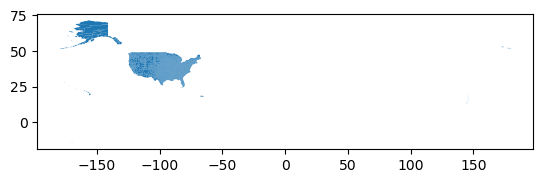

In [23]:
counties.columns = counties.columns.str.lower()
counties = counties.rename(columns={
    'statefp': "state_fp",
    'countyfp':'county_fp',
    'countyns':'county_ns',
    'namelsad':'name_lsad'})
counties.columns

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

In [24]:
# Finding the `state_fp` ID for New York using New York County, New York
counties[counties['name'] == 'New York']['state_fp']

1681    36
Name: state_fp, dtype: object

In [25]:
ny_counties = counties[counties['state_fp'] == '36']
ny_counties['name'].nunique()

62

<Axes: >

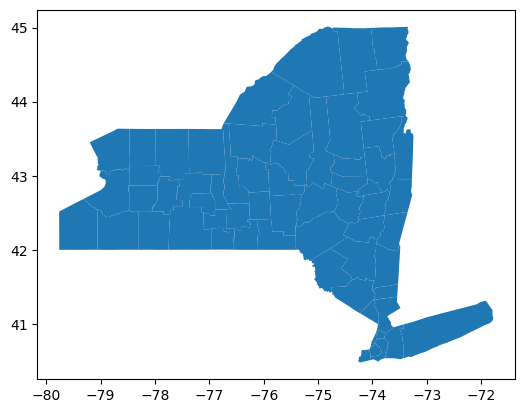

In [26]:
ny_counties.plot()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


In [27]:
ny_counties['name'].unique()

array(['Erie', 'Niagara', 'Jefferson', 'Steuben', 'Seneca', 'Rensselaer',
       'Albany', 'Saratoga', 'Schoharie', 'Schenectady', 'Ulster',
       'Dutchess', 'Orange', 'Columbia', 'Tompkins', 'Tioga', 'Broome',
       'Cayuga', 'Genesee', 'Onondaga', 'Oswego', 'Madison', 'Livingston',
       'Monroe', 'Ontario', 'Orleans', 'Wayne', 'Chautauqua', 'Sullivan',
       'Chemung', 'Cattaraugus', 'Fulton', 'Montgomery', 'Cortland',
       'Warren', 'Washington', 'Otsego', 'Queens', 'Bronx', 'Nassau',
       'Westchester', 'Richmond', 'Kings', 'Suffolk', 'Rockland',
       'New York', 'Putnam', 'Clinton', 'St. Lawrence', 'Herkimer',
       'Oneida', 'Yates', 'Greene', 'Schuyler', 'Delaware', 'Hamilton',
       'Lewis', 'Allegany', 'Chenango', 'Wyoming', 'Franklin', 'Essex'],
      dtype=object)

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

In [28]:
spills_per_county['county'].nunique()

66

<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [29]:
a = spills_per_county['county'].sort_values().unique()
b = ny_counties['name'].sort_values().unique()

diff_names_spills = np.setdiff1d(a, b)
diff_names_spills


array(['New Jersey - Region 2', 'Onondaga Indian Reservation',
       'Pennsylvania - Region 3', 'St Lawrence',
       'Tuscarora Indian Reservation'], dtype=object)

In [30]:
grader.check("7Ac")

7Ac results: All test cases passed!

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [31]:
diff_names_ny = np.setdiff1d(b, a)
diff_names_ny

array(['St. Lawrence'], dtype=object)

In [32]:
grader.check("7Ad")

7Ad results: All test cases passed!

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?

In [33]:
# e. 
print(f"Tuscarora Indian Reservation: {spills_per_county[spills_per_county['county'] == 'Tuscarora Indian Reservation']['n_spills'].tolist()} spill(s)")
print(f"Onondaga Indian Reservation: {spills_per_county[spills_per_county['county'] == 'Onondaga Indian Reservation']['n_spills'].tolist()} spill(s)")

Tuscarora Indian Reservation: [2] spill(s)
Onondaga Indian Reservation: [1] spill(s)


### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


In [34]:
# Pulling from original error message and instructor code
spills_per_county = spills_per_county.replace({'county': {'St Lawrence':'St. Lawrence'}})
spills_per_county[spills_per_county['county'] == 'St. Lawrence']

,county,n_spills
52,St. Lawrence,95


In [35]:
assert spills_per_county.loc[52]['county'] == 'St. Lawrence', f"Rename 'county' to St. Lawrence, got St Lawrence."

### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


In [36]:
# a 
spills_per_county = spills_per_county.rename(columns={'county':'county_name'})
ny_counties = ny_counties.rename(columns={'name':'county_name'})

b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


In [37]:
ny_spills = pd.merge(spills_per_county,
                     ny_counties, 
                     how = 'inner', 
                     on = 'county_name')

<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

In [38]:
c = spills_per_county['county_name'].sort_values().unique()
d = ny_spills['county_name'].sort_values().unique()

dropped_spills = np.setdiff1d(c, d)
dropped_spills

array(['New Jersey - Region 2', 'Onondaga Indian Reservation',
       'Pennsylvania - Region 3', 'Tuscarora Indian Reservation'],
      dtype=object)

In [39]:
dropped_cols = dropped_spills.tolist()
dropped_spills = spills_per_county[spills_per_county['county_name'].isin(dropped_cols)]
dropped_spills

,county_name,n_spills
30,New Jersey - Region 2,9
35,Onondaga Indian Reservation,1
41,Pennsylvania - Region 3,1
58,Tuscarora Indian Reservation,2


In [40]:
dropped_spills['n_spills'].sum()

13

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

_Yes, dropping these records removes 13 spills from the visualization, including spills on two Indian Reservations. As a result, our output map will not display spills on Indigenous land._

<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

In [41]:
# `n_spills` in Niagara county = 137 + 1 = 138
ny_spills.iloc[31,1] = 138
ny_spills[ny_spills['county_name'] == "Niagara"]

,county_name,n_spills,state_fp,county_fp,county_ns,geoid,geoidfq,name_lsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry
31,Niagara,138,36,063,00974130,36063,0500000US36063,Niagara County,06,H1,G4020,160,15380,None,A,1352876142,1598772310,+43.2726719,-078.8129431,"POLYGON ((-78.49165 43.08396, -78.49179 43.084..."


In [42]:
# `n_spills` in Onondaga county = 261 + 1 = 262
ny_spills.iloc[33,1] = 262
ny_spills[ny_spills['county_name'] == "Onondaga"]

,county_name,n_spills,state_fp,county_fp,county_ns,geoid,geoidfq,name_lsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry
33,Onondaga,262,36,067,00974132,36067,0500000US36067,Onondaga County,06,H1,G4020,532,45060,None,A,2016027811,70512841,+43.0065163,-076.1961336,"POLYGON ((-76.08017 42.78160, -76.08018 42.780..."


In [43]:
ny_spills.head()

,county_name,n_spills,state_fp,county_fp,county_ns,geoid,geoidfq,name_lsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry
0,Albany,311,36,001,00974099,36001,0500000US36001,Albany County,06,H1,G4020,104,10580,None,A,1354273428,26971923,+42.5882401,-073.9740095,"POLYGON ((-73.96379 42.44162, -73.96666 42.441..."
1,Allegany,44,36,003,00974100,36003,0500000US36003,Allegany County,06,H1,G4020,None,None,None,A,2666410162,12989705,+42.2478532,-078.0261531,"POLYGON ((-78.04342 42.51846, -78.04326 42.518..."
2,Bronx,192,36,005,00974101,36005,0500000US36005,Bronx County,06,H6,G4020,408,35620,35614,C,109301867,39287123,+40.8487111,-073.8529390,"POLYGON ((-73.93381 40.88221, -73.93365 40.882..."
3,Broome,101,36,007,00974102,36007,0500000US36007,Broome County,06,H1,G4020,None,13780,None,A,1827626584,25078248,+42.1619773,-075.8302833,"POLYGON ((-75.74223 41.99805, -75.75080 41.997..."
4,Cattaraugus,54,36,009,00974103,36009,0500000US36009,Cattaraugus County,06,H1,G4020,160,36460,None,A,3388177044,36783591,+42.2390986,-078.6623320,"POLYGON ((-78.69725 41.99867, -78.69881 41.998..."


<Axes: >

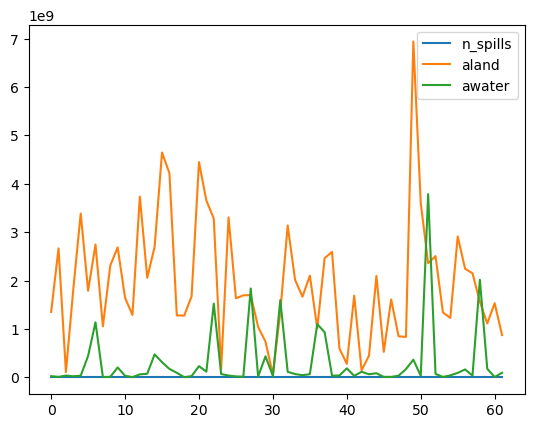

In [49]:
ny_spills.plot()

## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



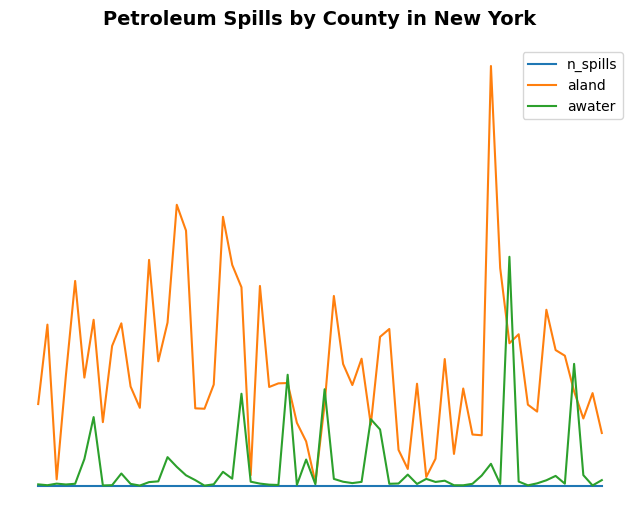

In [45]:
fig, ax = plt.subplots(figsize=(8,6))

ax.axis('off')

ny_spills.plot(ax=ax,
                column='n_spills',
                legend=True)

ax.set_title('Petroleum Spills by County in New York',
             fontsize=14, weight='bold', pad=15)

plt.show()

b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.

## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.